# Mission Summary

Full-mission Δv budget and timeline, read from each stage's archive in `trajectories/`:

1. `interplanetary-<mission>`: Lambert reference epochs
2. `departure-<mission>`: Earth escape burn and midcourse correction
3. `arrival-<mission>`: Mars capture (direct injection)
4. `rpo-<mission>`: rendezvous, nominal and dispersed cases

Run the stage notebooks in that order first, or set `RERUN_STAGES = True` below to do it from here. Ascent to the parking orbit and the Earth
escape burn are booked to the launch vehicle / upper stage, and everything after them to the
spacecraft. Ascent numbers are **ideal** (no drag, gravity or steering losses). The Mars
surface ↔ orbit Δv is a reference for a future lander (no aerobraking) and is not in the totals.

In [19]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from pathlib import Path

import numpy as np
import plotly.graph_objects as go
from cesium.constants import DAY_TO_SEC, HOUR_TO_SEC, KM_TO_M, M_TO_KM, RAD_TO_DEG
from cesium.guidance.hcw import RPO_PHASES
from cesium.math.time import jd_to_greg
from mission_io import load_mission, run_pipeline

In [ ]:
# Regenerate everything upstream before loading: departure -> ground_segment -> arrival -> rpo
# (each runs headless in its own process; archives and figures are rewritten, notebook outputs are not)
RERUN_STAGES = False
RERUN_INTERPLANETARY = False  # slow; only needed when the trajectory choice changes

if RERUN_STAGES:
    run_pipeline(include_interplanetary=RERUN_INTERPLANETARY, include_summary=False)

In [ ]:
MISSION_NAME = "birthday-christmas-earlier"
interplanetary = load_mission("interplanetary", MISSION_NAME)
departure = load_mission("departure", MISSION_NAME)
arrival = load_mission("arrival", MISSION_NAME)
rpo = load_mission("rpo", MISSION_NAME)

for stage, archive, keys in (
    ("departure", departure, ("dv_ascent_ideal_m_s", "dv_escape_m_s", "dv_midcourse_m_s")),
    ("arrival", arrival, ("dv_capture_m_s", "dv_surface_ideal_m_s")),
):
    missing = [k for k in keys if k not in archive.files]
    if missing:
        raise KeyError(f"{stage} archive lacks {missing}; rerun {stage}.ipynb to regenerate it")

CASES = [str(c) for c in rpo["cases"]]  # ["nominal", "dispersed"]


def greg(jd):
    """JD -> 'YYYY-MM-DD HH:MM' (TDB, as used throughout)."""
    y, mo, d, h, mi, _ = jd_to_greg(float(jd))
    return f"{y:04.0f}-{mo:02.0f}-{d:02.0f} {h:02.0f}:{mi:02.0f}"

## Timeline

In [22]:
t_launch = float(departure["epoch_jd"])
t_capture = float(arrival["epoch_jd"])
events = [
    ("Earth escape burn (parking-orbit periapsis)", t_launch),
    ("Lambert departure reference", float(interplanetary["lambert_departure_jd"])),
    ("Midcourse correction", float(departure["midcourse_epoch_jd"])),
    ("Mars capture burn (periapsis)", t_capture),
] + [
    (f"Docking ({case})", float(rpo["epoch_jd"]) + float(rpo[f"{case}_t_dock_s"]) / DAY_TO_SEC)
    for case in CASES
]
events.sort(key=lambda e: e[1])

print(f"{'event':<46}{'date (TDB)':<20}{'T+ [days]':>10}")
print("-" * 76)
for name, jd in events:
    print(f"{name:<46}{greg(jd):<20}{jd - t_launch:>10.2f}")
print(f"\nCruise (escape -> capture): {t_capture - t_launch:.2f} days")
for case in CASES:
    print(f"RPO duration ({case}): {float(rpo[f'{case}_t_dock_s']) / HOUR_TO_SEC:.1f} hr")

event                                         date (TDB)           T+ [days]
----------------------------------------------------------------------------
Lambert departure reference                   2035-06-14 12:00         -0.42
Earth escape burn (parking-orbit periapsis)   2035-06-14 22:04          0.00
Midcourse correction                          2035-06-17 21:35          2.98
Mars capture burn (periapsis)                 2035-12-25 00:00        193.08
Docking (nominal)                             2035-12-26 16:30        194.77
Docking (dispersed)                           2035-12-26 18:56        194.87

Cruise (escape -> capture): 193.08 days
RPO duration (nominal): 40.5 hr
RPO duration (dispersed): 42.9 hr


## Δv budget

In [23]:
# One row per maneuver; RPO differs by case
budget = [
    {"maneuver": "Earth ascent to LEO (ideal)", "vehicle": "launch vehicle", "dv": {c: float(departure["dv_ascent_ideal_m_s"]) for c in CASES}},
    {"maneuver": "Earth escape", "vehicle": "launch vehicle", "dv": {c: float(departure["dv_escape_m_s"]) for c in CASES}},
    {"maneuver": "Midcourse correction", "vehicle": "spacecraft", "dv": {c: float(departure["dv_midcourse_m_s"]) for c in CASES}},
    {"maneuver": "Mars capture (direct injection)", "vehicle": "spacecraft", "dv": {c: float(arrival["dv_capture_m_s"]) for c in CASES}},
    {"maneuver": "RPO", "vehicle": "spacecraft", "dv": {c: float(rpo[f"{c}_dv_total_m_s"]) for c in CASES}},
]
# Not in this mission's totals: ideal lander descent/ascent at the Perseverance site
reference = [
    {"maneuver": "Mars surface <-> orbit (ideal)", "vehicle": "reference", "dv": {c: float(arrival["dv_surface_ideal_m_s"]) for c in CASES}},
]
DV_COPLANAR_MIN = float(arrival["dv_coplanar_min_m_s"])


def budget_table(budget):
    lines = [f"{'maneuver':<34}{'vehicle':<17}" + "".join(f"{c + ' [m/s]':>18}" for c in CASES), "-" * (51 + 18 * len(CASES))]
    for row in budget:
        lines.append(f"{row['maneuver']:<34}{row['vehicle']:<17}" + "".join(f"{row['dv'][c]:>18.1f}" for c in CASES))
    lines.append("-" * (51 + 18 * len(CASES)))
    for vehicle in ("spacecraft", "launch vehicle"):
        tot = {c: sum(r["dv"][c] for r in budget if r["vehicle"] == vehicle) for c in CASES}
        lines.append(f"{'total, ' + vehicle:<51}" + "".join(f"{tot[c]:>18.1f}" for c in CASES))
    grand = {c: sum(r["dv"][c] for r in budget) for c in CASES}
    lines.append(f"{'total, all':<51}" + "".join(f"{grand[c]:>18.1f}" for c in CASES))
    lines.append("")
    for row in reference:
        lines.append(f"{row['maneuver'] + ' *':<34}{'not in totals':<17}" + "".join(f"{row['dv'][c]:>18.1f}" for c in CASES))
    lines.append("* ideal: no drag, gravity losses, aerobraking or parachutes")
    lines.append(
        f"\nCapture reference: coplanar minimum {DV_COPLANAR_MIN:.1f} m/s; "
        f"direct injection pays {float(arrival['dv_capture_m_s']) - DV_COPLANAR_MIN:.1f} m/s for the plane change "
        f"(beta = {float(arrival['beta_rad']) * RAD_TO_DEG:.1f} deg)"
    )
    return "\n".join(lines)


print(budget_table(budget))

maneuver                          vehicle               nominal [m/s]   dispersed [m/s]
---------------------------------------------------------------------------------------
Earth ascent to LEO (ideal)       launch vehicle               7790.7            7790.7
Earth escape                      launch vehicle               3675.6            3675.6
Midcourse correction              spacecraft                    131.8             131.8
Mars capture (direct injection)   spacecraft                   5524.4            5524.4
RPO                               spacecraft                     80.6             248.7
---------------------------------------------------------------------------------------
total, spacecraft                                              5736.8            5905.0
total, launch vehicle                                         11466.3           11466.3
total, all                                                    17203.1           17371.3

Mars surface <-> orbit (ideal) 

In [24]:
# RPO by phase, per case
present = {str(p) for c in CASES for p in rpo[f"{c}_phase_names"]}
phase_names = [label for label, _ in RPO_PHASES if label in present]  # mission order
print(f"{'RPO phase':<26}" + "".join(f"{c + ' [m/s]':>18}" for c in CASES))
print("-" * (26 + 18 * len(CASES)))
for ph in phase_names:
    vals = []
    for c in CASES:
        names, dvs = list(rpo[f"{c}_phase_names"]), rpo[f"{c}_phase_dv_m_s"]
        vals.append(dvs[names.index(ph)] if ph in names else 0.0)
    print(f"{ph:<26}" + "".join(f"{v:>18.2f}" for v in vals))
print("-" * (26 + 18 * len(CASES)))
print(f"{'total':<26}" + "".join(f"{float(rpo[f'{c}_dv_total_m_s']):>18.2f}" for c in CASES))
print(f"{'final miss [m]':<26}" + "".join(f"{float(rpo[f'{c}_miss_m']):>18.2f}" for c in CASES))

RPO phase                      nominal [m/s]   dispersed [m/s]
--------------------------------------------------------------
Plane change                            0.00            129.97
Hohmann + phase entry                  14.97             58.39
Phasing                                11.13             10.62
Phase exit                             20.90             10.58
HCW terminal                           33.57             39.14
--------------------------------------------------------------
total                                  80.57            248.70
final miss [m]                          6.91              4.79


## Δv chart
One bar per maneuver, colored by vehicle; RPO shown for both cases. The tick on the capture bar marks the coplanar minimum.

In [25]:
# Reference palette: categorical slots 1-3, in fixed order
VEHICLE_COLOR = {"spacecraft": "#2a78d6", "launch vehicle": "#eb6834", "reference": "#1baf7a"}
VEHICLE_LABEL = {"spacecraft": "spacecraft", "launch vehicle": "launch vehicle", "reference": "reference (not in totals)"}
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3dd"

bars = [r for r in budget if r["maneuver"] != "RPO"] + reference + [
    {"maneuver": f"RPO ({c})", "vehicle": "spacecraft", "dv": {c2: next(r for r in budget if r["maneuver"] == "RPO")["dv"][c] for c2 in CASES}}
    for c in CASES
]
labels = [b["maneuver"] for b in bars][::-1]  # first maneuver on top
values_km = [b["dv"][CASES[0]] * M_TO_KM for b in bars][::-1]
vehicles = [b["vehicle"] for b in bars][::-1]

fig_budget = go.Figure()
for vehicle, color in VEHICLE_COLOR.items():
    idx = [i for i, v in enumerate(vehicles) if v == vehicle]
    fig_budget.add_bar(
        y=[labels[i] for i in idx],
        x=[values_km[i] for i in idx],
        orientation="h",
        name=VEHICLE_LABEL[vehicle],
        marker={"color": color, "line": {"color": SURFACE, "width": 2}, "cornerradius": 4},
        text=[f"{values_km[i]:.3f} km/s" if values_km[i] >= 1 else f"{values_km[i] * KM_TO_M:.0f} m/s" for i in idx],
        textposition="outside",
        textfont={"color": INK_2, "size": 12},
        hovertemplate="%{y}<br>%{x:.3f} km/s<extra>" + VEHICLE_LABEL[vehicle] + "</extra>",
        cliponaxis=False,
    )
cap_label = "Mars capture (direct injection)"
fig_budget.add_scatter(
    x=[DV_COPLANAR_MIN * M_TO_KM],
    y=[cap_label],
    mode="markers",
    name="coplanar capture minimum",
    marker={"symbol": "line-ns", "size": 22, "line": {"width": 2, "color": INK}},
    hovertemplate=f"coplanar minimum<br>{DV_COPLANAR_MIN * M_TO_KM:.3f} km/s<extra></extra>",
)
sc = {c: sum(r["dv"][c] for r in budget if r["vehicle"] == "spacecraft") for c in CASES}
lv = sum(r["dv"][CASES[0]] for r in budget if r["vehicle"] == "launch vehicle")
fig_budget.update_layout(
    title=(
        f"Mission Δv budget: spacecraft {sc[CASES[0]] * M_TO_KM:.2f}-{sc[CASES[-1]] * M_TO_KM:.2f} km/s "
        f"+ launch vehicle {lv * M_TO_KM:.2f} km/s (ideal ascent + escape)"
    ),
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font={"color": INK},
    barmode="overlay",
    bargap=0.35,
    height=470,
    margin={"l": 230, "r": 90, "t": 70, "b": 50},
    legend={"orientation": "h", "y": -0.18, "x": 0},
    xaxis={"title": "Δv [km/s]", "gridcolor": GRID, "zeroline": False, "rangemode": "tozero"},
    yaxis={"categoryorder": "array", "categoryarray": labels},
)
fig_budget.show()

$4270$ m/s according to this map:
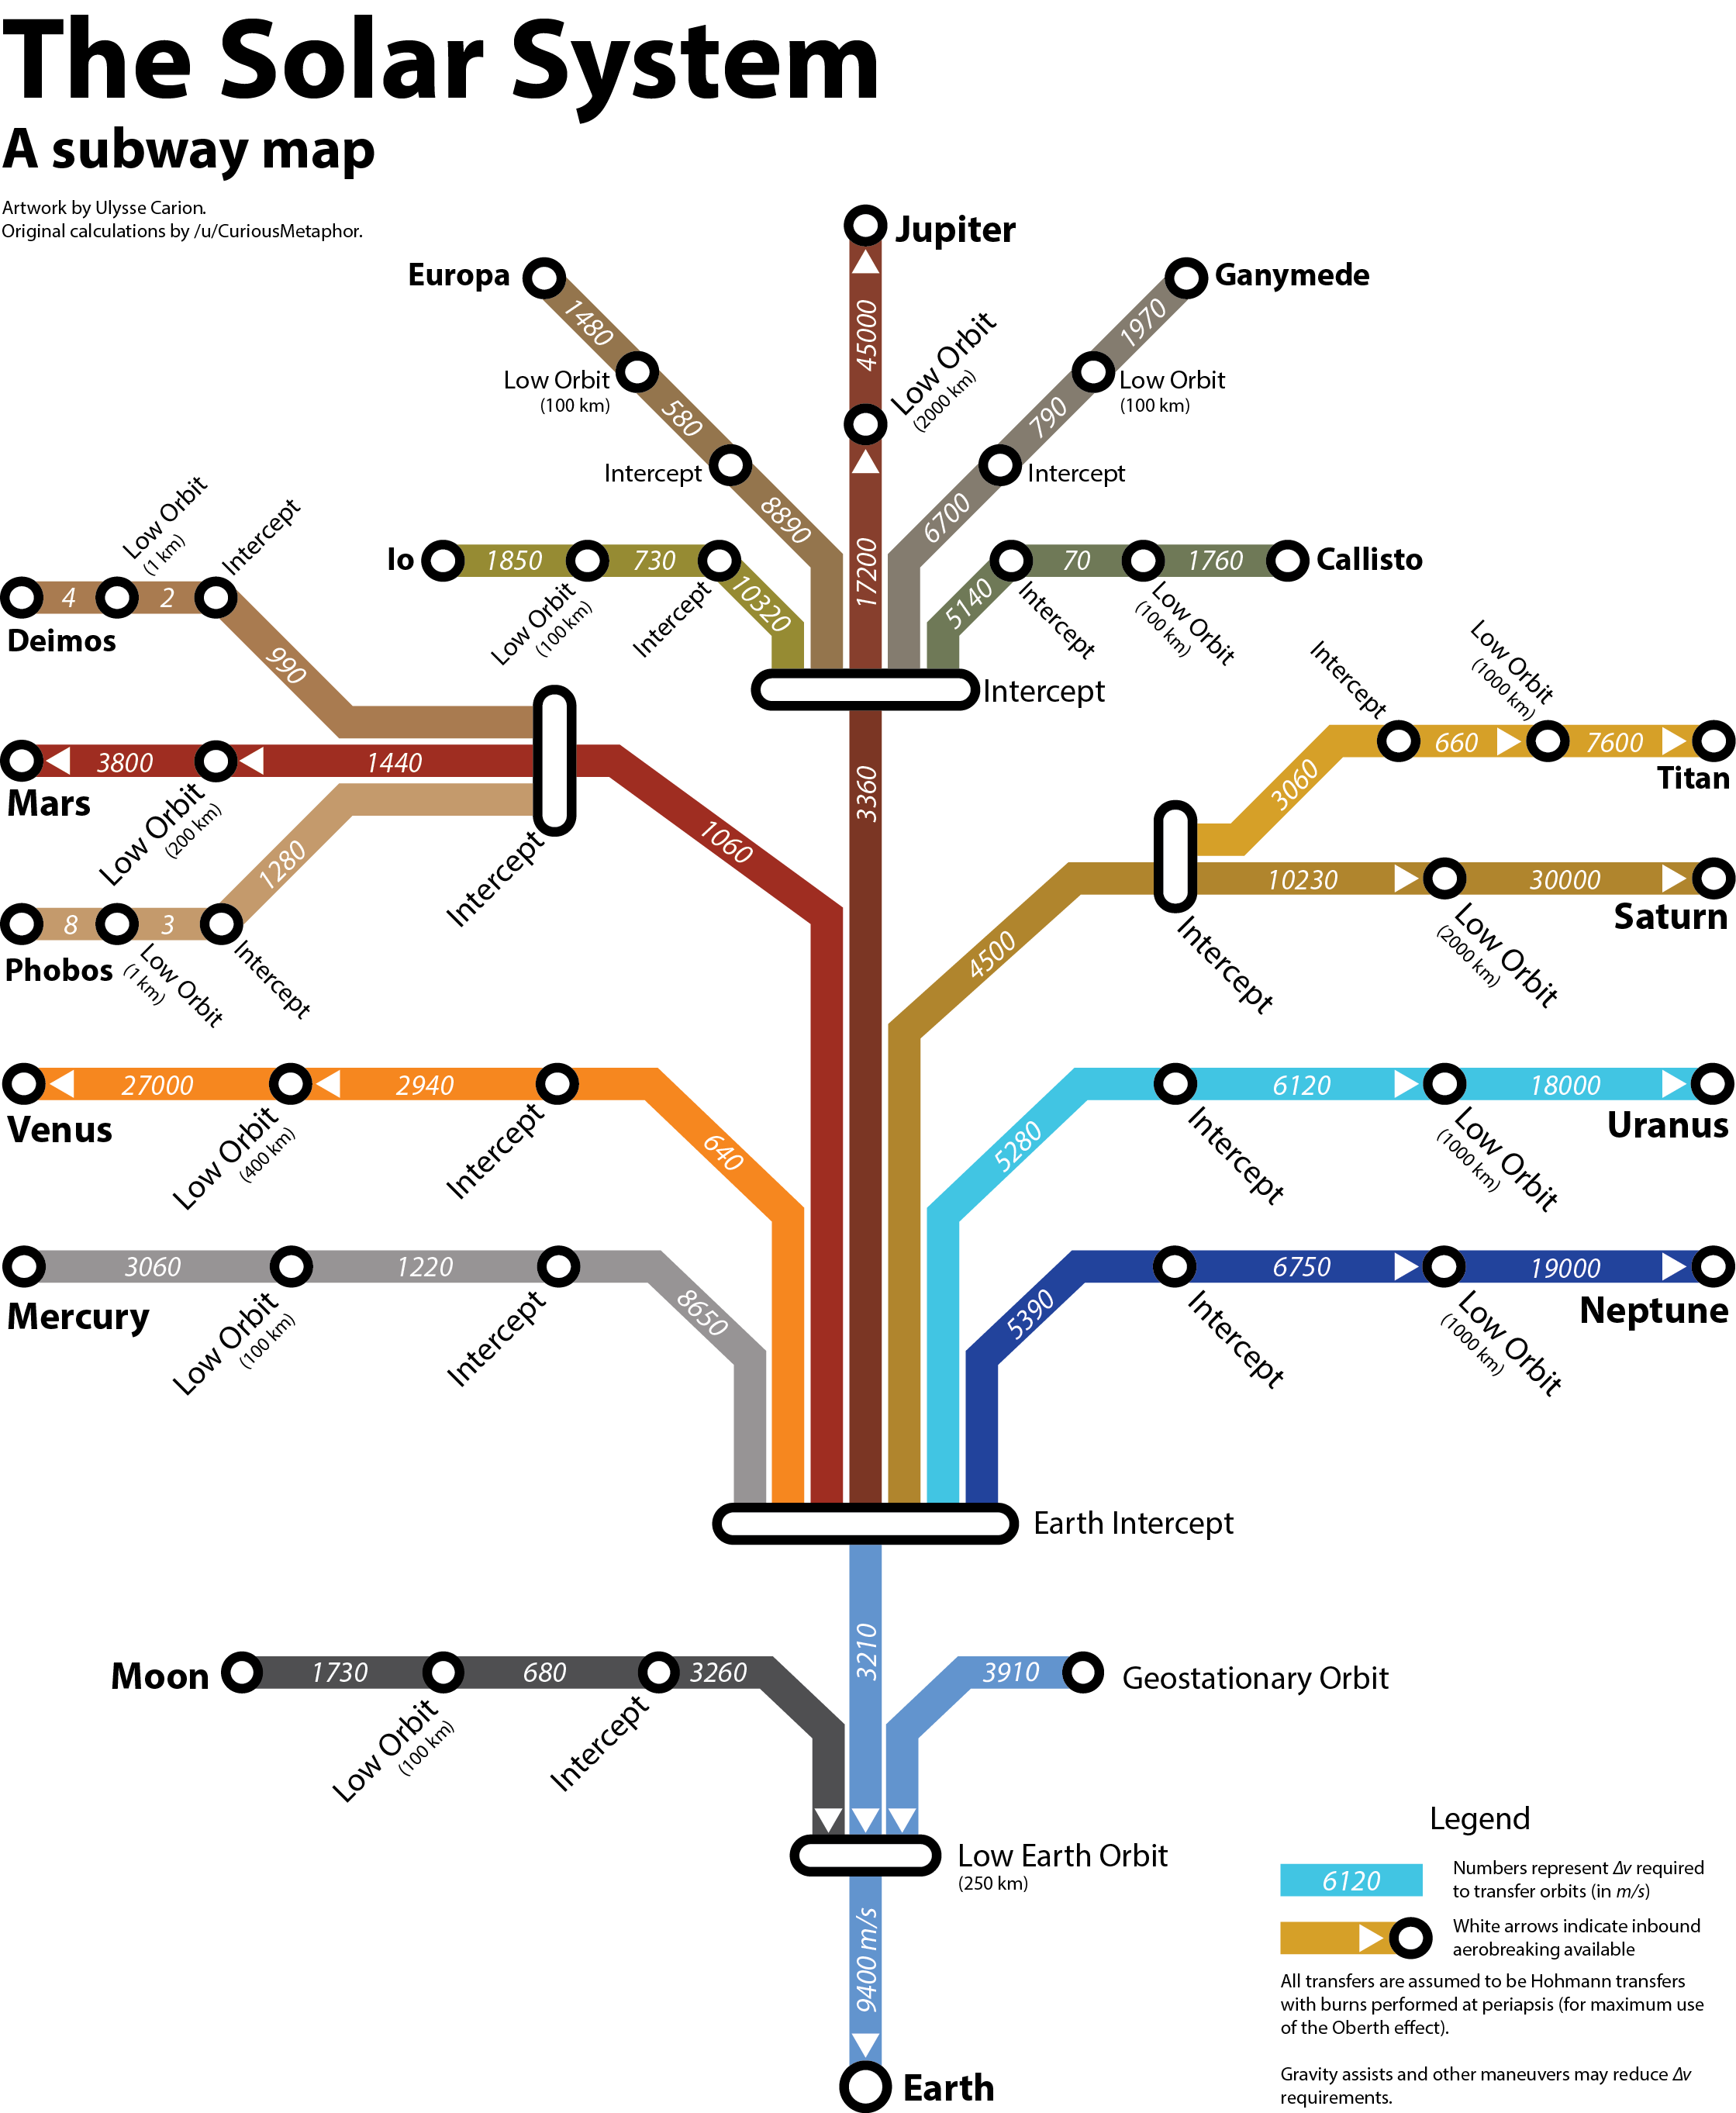

In [28]:
# Napkin: Falcon Heavy + Perseverance-class payload through this spacecraft dv budget.
# Rough public figures and ASSUMPTIONS (marked); edit freely. Not a launch-vehicle analysis.
G0 = 9.80665  # m/s^2

LV_MARS_KG = 16_800  # FH expendable payload to Mars injection (SpaceX published); covers ascent + escape
LV_PRICE_USD = 150e6  # ASSUMPTION: expendable FH (~$97M list price is for the reusable config)
LV_PROP_KG = {"LOX": 935e3, "RP-1": 396e3}  # ASSUMPTION: ~1,420 t liftoff, ~95% propellant, O/F ~2.36

PROP_USD_PER_KG = {"LOX": 0.25, "RP-1": 2.5}  # ASSUMPTION: bulk prices
ROVER_KG = 1_025  # Perseverance rover
MARS2020_LAUNCH_KG = 4_050  # Mars 2020 at launch: rover + cruise stage + EDL system + propellant
ISP_S = 320  # ASSUMPTION: storable biprop (MMH/NTO) main engine
TANKAGE = 0.10  # ASSUMPTION: tanks + engines + structure per kg of propellant
SC_PROP_USD_PER_KG = 200  # ASSUMPTION: storable biprop incl. loading/handling

LV_fuel_usd = sum(LV_PROP_KG[p] * PROP_USD_PER_KG[p] for p in LV_PROP_KG)
dv_sc = {c: sum(r["dv"][c] for r in budget if r["vehicle"] == "spacecraft") for c in CASES}
dv_sc["coplanar capture"] = dv_sc[CASES[0]] - float(arrival["dv_capture_m_s"]) + DV_COPLANAR_MIN

print(f"FH propellant: {sum(LV_PROP_KG.values()) / 1e3:,.0f} t -> ${LV_fuel_usd / 1e6:.2f}M "
      f"({LV_fuel_usd / LV_PRICE_USD:.1%} of a ${LV_PRICE_USD / 1e6:.0f}M launch)\n")
print(f"{'case':<18}{'dv [km/s]':>10}{'m0/mf':>7}{'prop [t]':>10}{'useful [t]':>11}"
      f"{'rovers':>8}{'SC fuel $M':>11}{'$k / useful kg':>16}")
for label, dv in dv_sc.items():
    mass_ratio = np.exp(dv / (ISP_S * G0))  # Tsiolkovsky
    m_prop = LV_MARS_KG * (1 - 1 / mass_ratio)
    m_useful = LV_MARS_KG / mass_ratio - TANKAGE * m_prop  # docked, minus propulsion hardware
    cost = LV_PRICE_USD + m_prop * SC_PROP_USD_PER_KG
    print(f"{label:<18}{dv * M_TO_KM:>10.2f}{mass_ratio:>7.2f}{m_prop / 1e3:>10.1f}{m_useful / 1e3:>11.2f}"
          f"{m_useful / ROVER_KG:>8.2f}{m_prop * SC_PROP_USD_PER_KG / 1e6:>11.2f}"
          f"{cost / max(m_useful, 1) / 1e3:>16.1f}")
print(f"\nFor scale: Mars 2020 launched at {MARS2020_LAUNCH_KG:,} kg on an Atlas V and entered the atmosphere "
      f"directly (no propulsive capture); {LV_MARS_KG / MARS2020_LAUNCH_KG:.1f}x that fits on an FH to Mars.")

FH propellant: 1,331 t -> $1.22M (0.8% of a $150M launch)

case               dv [km/s]  m0/mf  prop [t] useful [t]  rovers SC fuel $M  $k / useful kg
nominal                 5.74   6.22      14.1       1.29    1.26       2.82           118.5
dispersed               5.90   6.56      14.2       1.14    1.11       2.85           134.7
coplanar capture        2.39   2.14       8.9       6.96    6.79       1.79            21.8

For scale: Mars 2020 launched at 4,050 kg on an Atlas V and entered the atmosphere directly (no propulsive capture); 4.1x that fits on an FH to Mars.


## Presentation plots
Built from the stage archives and the napkin inputs above, so they stay consistent with the tables.

In [ ]:
# Shared style: reference palette slots in fixed order, recessive grid, text in ink (never series color)
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow


def style(fig, title, height=520, **layout):
    base = {
        "template": "plotly_white",
        "paper_bgcolor": SURFACE,
        "plot_bgcolor": SURFACE,
        "font": {"color": INK, "size": 13},
        "margin": {"l": 70, "r": 40, "t": 70, "b": 60},
        "legend": {"orientation": "h", "y": -0.15, "x": 0},
    }
    fig.update_layout(title=title, height=height, **(base | layout))  # callers may override defaults
    fig.update_xaxes(gridcolor=GRID, zeroline=False)
    fig.update_yaxes(gridcolor=GRID, zeroline=False)
    return fig

In [ ]:
# 1. Heliocentric transfer, ecliptic top view
from cesium.constants import AU_TO_M
from cesium.orbital.ephemeris import planet_elements_and_rv

AU_KM = AU_TO_M * M_TO_KM
jd0 = float(interplanetary["lambert_departure_jd"])
r_sc = interplanetary["satellite_rv_hci_km"][:, 0:3] / AU_KM
r_earth = interplanetary["earth_rv_hci_km"][:, 0:3] / AU_KM
r_mars = interplanetary["mars_rv_hci_km"][:, 0:3] / AU_KM


def orbit_ring(planet, period_days, n=400):
    jds = jd0 + np.linspace(0, period_days, n)
    return np.array([planet_elements_and_rv(planet, jd)[1] for jd in jds]) / AU_TO_M


ring_earth, ring_mars = orbit_ring(3, 365.25), orbit_ring(4, 687.0)

fig_helio = go.Figure()
for ring, name, color in ((ring_earth, "Earth orbit", SLOT[2]), (ring_mars, "Mars orbit", SLOT[1])):
    fig_helio.add_scatter(x=ring[:, 0], y=ring[:, 1], mode="lines", name=name,
                          line={"color": color, "width": 1, "dash": "dot"}, hoverinfo="skip")
fig_helio.add_scatter(x=r_sc[:, 0], y=r_sc[:, 1], mode="lines", name="Courier transfer",
                      line={"color": SLOT[0], "width": 3},
                      customdata=interplanetary["time_s"] / DAY_TO_SEC,
                      hovertemplate="day %{customdata:.0f}<br>x %{x:.3f} AU, y %{y:.3f} AU<extra></extra>")
markers = [
    (r_earth[0], "Earth at departure", SLOT[2], f"Launch {greg(jd0)[:10]}"),
    (r_mars[0], "Mars at departure", SLOT[1], "Mars at launch"),
    (r_mars[-1], "Mars at arrival", SLOT[1], f"Arrival {greg(float(interplanetary['lambert_arrival_jd']))[:10]}"),
]
for r, name, color, label in markers:
    fig_helio.add_scatter(x=[r[0]], y=[r[1]], mode="markers+text", name=name, showlegend=False,
                          text=[label], textposition="top center", textfont={"color": INK_2},
                          marker={"color": color, "size": 11, "line": {"color": SURFACE, "width": 2}})
fig_helio.add_scatter(x=[0], y=[0], mode="markers+text", text=["Sun"], textposition="bottom center",
                      marker={"color": SLOT[3], "size": 16}, showlegend=False, textfont={"color": INK_2})
style(fig_helio, f"Earth→Mars transfer: {float(interplanetary['tof_s']) / DAY_TO_SEC:.1f} days (ecliptic, HCI)", height=850)
fig_helio.update_xaxes(title="x [AU]")
fig_helio.update_yaxes(title="y [AU]", scaleanchor="x")
fig_helio.show()

In [ ]:
# 2. Spacecraft mass through the mission (one FH injection, rocket equation per burn)
def mass_history(dv_list):
    m = [LV_MARS_KG]
    for dv in dv_list:
        m.append(m[-1] / np.exp(dv / (ISP_S * G0)))
    m_prop = LV_MARS_KG - m[-1]
    return np.array(m), m[-1] - TANKAGE * m_prop


steps = ["Injected by FH", "After midcourse", "After capture", "After RPO (docked)"]
dv_mid = float(departure["dv_midcourse_m_s"])
dv_rpo = float(rpo[f"{CASES[0]}_dv_total_m_s"])
plans = {
    f"direct injection ({float(arrival['dv_capture_m_s']) * M_TO_KM:.2f} km/s capture)": [dv_mid, float(arrival["dv_capture_m_s"]), dv_rpo],
    f"coplanar capture ({DV_COPLANAR_MIN * M_TO_KM:.2f} km/s capture)": [dv_mid, DV_COPLANAR_MIN, dv_rpo],
}
fig_mass = go.Figure()
for k, (label, dvs) in enumerate(plans.items()):
    m, useful = mass_history(dvs)
    fig_mass.add_bar(x=steps + ["Useful payload"], y=np.append(m, useful) / 1e3, name=label,
                     marker={"color": SLOT[k], "line": {"color": SURFACE, "width": 2}, "cornerradius": 4},
                     text=[f"{v / 1e3:.1f} t" for v in np.append(m, useful)], textposition="outside",
                     textfont={"color": INK_2}, hovertemplate="%{x}<br>%{y:.2f} t<extra>" + label + "</extra>")
fig_mass.add_hline(y=ROVER_KG / 1e3, line={"color": INK_2, "dash": "dash", "width": 1},
                   annotation_text="Perseverance rover (1.03 t)", annotation_position="top left",
                   annotation_font={"color": INK_2})
style(fig_mass, f"Spacecraft mass from one Falcon Heavy ({ISP_S} s Isp, {TANKAGE:.0%} tankage)", barmode="group")
fig_mass.update_yaxes(title="mass [t]")
fig_mass.show()

In [ ]:
# 3. Capture trade: useful payload vs capture dv (midcourse + nominal RPO held fixed)
dv_cap = np.linspace(1.5e3, 6.0e3, 200)
useful_t = np.array([mass_history([dv_mid, d, dv_rpo])[1] for d in dv_cap]) / 1e3
fig_trade = go.Figure()
fig_trade.add_scatter(x=dv_cap * M_TO_KM, y=useful_t, mode="lines", line={"color": SLOT[0], "width": 2},
                      showlegend=False, hovertemplate="capture %{x:.2f} km/s<br>useful %{y:.2f} t<extra></extra>")
for d, name in ((DV_COPLANAR_MIN, "coplanar minimum"), (float(arrival["dv_capture_m_s"]), "direct injection (current)")):
    u = mass_history([dv_mid, d, dv_rpo])[1] / 1e3
    fig_trade.add_scatter(x=[d * M_TO_KM], y=[u], mode="markers+text", showlegend=False,
                          text=[f"{name}<br>{u:.2f} t ({u * 1e3 / ROVER_KG:.1f} rovers)"],
                          textposition="top right" if d < 4e3 else "top left",
                          textfont={"color": INK_2}, marker={"color": SLOT[0], "size": 10, "line": {"color": SURFACE, "width": 2}})
fig_trade.add_hline(y=ROVER_KG / 1e3, line={"color": INK_2, "dash": "dash", "width": 1},
                    annotation_text="one rover", annotation_position="bottom left", annotation_font={"color": INK_2})
style(fig_trade, "Mars capture Δv drives delivered payload (one Falcon Heavy)")
fig_trade.update_xaxes(title="capture Δv [km/s]")
fig_trade.update_yaxes(title="useful payload at target [t]", rangemode="tozero")
fig_trade.show()

In [ ]:
# 4. RPO dv by phase, nominal vs dispersed
fig_rpo = go.Figure()
for k, c in enumerate(CASES):
    names, dvs = list(rpo[f"{c}_phase_names"]), rpo[f"{c}_phase_dv_m_s"]
    vals = [float(dvs[names.index(ph)]) if ph in names else 0.0 for ph in phase_names]
    fig_rpo.add_bar(x=phase_names, y=vals, name=f"{c} ({float(rpo[f'{c}_dv_total_m_s']):.0f} m/s total)",
                    marker={"color": SLOT[k], "line": {"color": SURFACE, "width": 2}, "cornerradius": 4},
                    text=[f"{v:.0f}" if v >= 1 else "" for v in vals], textposition="outside",
                    textfont={"color": INK_2}, hovertemplate="%{x}<br>%{y:.1f} m/s<extra>" + c + "</extra>")
style(fig_rpo, "RPO Δv by phase: capture dispersions cost a plane change", barmode="group")
fig_rpo.update_yaxes(title="Δv [m/s]")
fig_rpo.show()

In [ ]:
# 5. Mission timeline: cruise in days (left), RPO zoomed in hours (right, dispersed case)
from plotly.subplots import make_subplots

t_mid = float(departure["midcourse_epoch_jd"])
cruise_phases = [
    ("Earth escape → midcourse", t_launch, t_mid),
    ("Cruise", t_mid, t_capture),
    ("Capture → docking", t_capture, t_capture + float(rpo[f"{CASES[-1]}_t_dock_s"]) / DAY_TO_SEC),
]
case_tl = CASES[-1]
b_t, b_names = rpo[f"{case_tl}_burn_t_s"], [str(n) for n in rpo[f"{case_tl}_burn_names"]]
rpo_phases = []
for label, prefixes in RPO_PHASES:
    ts_ = [t for t, n in zip(b_t, b_names) if n.startswith(prefixes)]
    if ts_:
        rpo_phases.append((label, min(ts_) / HOUR_TO_SEC, max(ts_) / HOUR_TO_SEC))

fig_timeline = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.14,
                             subplot_titles=("Mission [days since escape burn]", f"RPO [hours since capture, {case_tl}]"))
for k, (label, t0, t1) in enumerate(cruise_phases):
    fig_timeline.add_bar(y=[label], x=[t1 - t0], base=[t0 - t_launch], orientation="h", row=1, col=1,
                         marker={"color": SLOT[0], "cornerradius": 4}, showlegend=False,
                         text=[f"{t1 - t0:.1f} d"], textposition="outside", textfont={"color": INK_2},
                         hovertemplate=f"{label}<br>day %{{base:.2f}} → {t1 - t_launch:.2f}<extra></extra>")
for label, t0, t1 in rpo_phases:
    width = max(t1 - t0, 0.25)  # single-burn phases still show
    fig_timeline.add_bar(y=[label], x=[width], base=[t0], orientation="h", row=1, col=2,
                         marker={"color": SLOT[0], "cornerradius": 4}, showlegend=False,
                         text=[f"{t1 - t0:.1f} h" if t1 - t0 >= 0.5 else ""], textposition="outside",
                         textfont={"color": INK_2}, hovertemplate=f"{label}<br>%{{base:.2f}} → {t1:.2f} h<extra></extra>")
style(fig_timeline, f"Mission timeline: {greg(t_launch)[:10]} → {greg(t_capture)[:10]}", height=420)
fig_timeline.update_yaxes(autorange="reversed", gridcolor=GRID)
t_end_days = cruise_phases[-1][2] - t_launch
t_end_hours = max(t1 for _, _, t1 in rpo_phases)
fig_timeline.update_xaxes(title="days", range=[0, 1.12 * t_end_days], row=1, col=1)
fig_timeline.update_xaxes(title="hours", range=[0, 1.15 * t_end_hours], row=1, col=2)
fig_timeline.show()

In [ ]:
# 6. Range from Earth and Mars during cruise; one-way light time drives the comms slide
from cesium.constants import C_LIGHT

days = interplanetary["time_s"] / DAY_TO_SEC
d_earth = np.linalg.norm(r_sc - r_earth, axis=1)  # AU
d_mars = np.linalg.norm(r_sc - r_mars, axis=1)
light_min = d_earth * AU_TO_M / C_LIGHT / 60

fig_range = go.Figure()
for d, name, color in ((d_earth, "from Earth", SLOT[0]), (d_mars, "from Mars", SLOT[1])):
    fig_range.add_scatter(x=days, y=d, mode="lines", name=name, line={"color": color, "width": 2},
                          customdata=light_min,
                          hovertemplate="day %{x:.0f}<br>%{y:.3f} AU" + ("<br>light time %{customdata:.1f} min" if name == "from Earth" else "") + "<extra></extra>")
fig_range.add_annotation(x=days[-1], y=d_earth[-1], text=f"{d_earth[-1]:.2f} AU<br>{light_min[-1]:.1f} min one-way",
                         showarrow=True, arrowhead=0, ax=-80, ay=-30, font={"color": INK_2})
style(fig_range, f"Spacecraft range during cruise (one-way light time at arrival {light_min[-1]:.1f} min)", height=450)
fig_range.update_xaxes(title="days since Lambert departure")
fig_range.update_yaxes(title="range [AU]", rangemode="tozero")
fig_range.show()

In [ ]:
# 7. Arrival B-plane: aim point vs Mars and the 300 km-periapsis locus
from cesium.world.constants import MU_MARS, R_MARS

v_inf_m = np.linalg.norm(arrival["v_inf_mci_km_s"]) * KM_TO_M
r_p_m = float(arrival["target_coes"][0])  # circular target: periapsis radius = a
b_of = lambda r_p: r_p * np.sqrt(1 + 2 * MU_MARS / (r_p * v_inf_m**2))  # aim radius for periapsis r_p
B_T, B_R = arrival["B_TR_m"] * M_TO_KM
phi = np.linspace(0, 2 * np.pi, 361)

fig_bplane = go.Figure()
fig_bplane.add_scatter(x=R_MARS * M_TO_KM * np.cos(phi), y=R_MARS * M_TO_KM * np.sin(phi), fill="toself",
                       fillcolor="rgba(193,68,14,0.30)", line={"color": "#c1440e", "width": 1}, name="Mars disk",
                       hoverinfo="skip")
fig_bplane.add_scatter(x=b_of(R_MARS) * M_TO_KM * np.cos(phi), y=b_of(R_MARS) * M_TO_KM * np.sin(phi), mode="lines",
                       line={"color": "#c1440e", "width": 1.5, "dash": "dash"},
                       name=f"impact radius {b_of(R_MARS) * M_TO_KM:,.0f} km (gravity focusing)", hoverinfo="skip")
fig_bplane.add_scatter(x=b_of(r_p_m) * M_TO_KM * np.cos(phi), y=b_of(r_p_m) * M_TO_KM * np.sin(phi), mode="lines",
                       line={"color": SLOT[0], "width": 2}, name=f"300 km periapsis locus |B| = {b_of(r_p_m) * M_TO_KM:,.0f} km",
                       hoverinfo="skip")
fig_bplane.add_scatter(x=[B_T], y=[B_R], mode="markers+text", name="aim point",
                       text=[f"aim point<br>B·T {B_T:,.0f} km, B·R {B_R:,.0f} km"], textposition="middle right",
                       textfont={"color": INK_2}, marker={"color": INK, "size": 11, "symbol": "x"})
style(fig_bplane, f"Arrival B-plane (v∞ = {v_inf_m * M_TO_KM:.2f} km/s, β = {float(arrival['beta_rad']) * RAD_TO_DEG:.1f}°)",
      height=750, legend={"orientation": "v", "y": 1.0, "x": 1.02})
fig_bplane.update_xaxes(title="B·T [km]")
fig_bplane.update_yaxes(title="B·R [km]", scaleanchor="x")
fig_bplane.show()

In [ ]:
# 8. RPO range on a log scale: phasing closes km by km, HCW closes the last 20 km
fig_logrange = go.Figure()
fig_logrange.update_yaxes(type="log")  # set before add_hline so y is in data units
for k, c in enumerate(CASES):
    t_h = rpo[f"{c}_time_s"] / HOUR_TO_SEC
    rng_m = np.linalg.norm(rpo[f"{c}_rv_chaser_mci_m"][:, 0:3] - rpo[f"{c}_rv_target_mci_m"][:, 0:3], axis=1)
    keep = t_h <= float(rpo[f"{c}_t_dock_s"]) / HOUR_TO_SEC + 1.0
    fig_logrange.add_scatter(x=t_h[keep][::5], y=np.maximum(rng_m[keep][::5], 1e-1), mode="lines",
                             name=f"{c} (miss {float(rpo[f'{c}_miss_m']):.1f} m)", line={"color": SLOT[k], "width": 2},
                             hovertemplate="t %{x:.2f} h<br>range %{y:,.1f} m<extra>" + c + "</extra>")
for y, label in ((15e3, "HCW linear region 15 km"), (200, "keep-out 200 m")):
    fig_logrange.add_hline(y=y, line={"color": INK_2, "dash": "dot", "width": 1})
    # annotations on a log axis take log10(y)
    fig_logrange.add_annotation(x=0.01, xref="x domain", y=np.log10(y), yref="y", text=label, showarrow=False,
                                xanchor="left", yanchor="top", font={"color": INK_2})
style(fig_logrange, "Chaser–target range through the RPO", height=480)
fig_logrange.update_xaxes(title="hours since capture")
fig_logrange.update_yaxes(title="range [m]", type="log", exponentformat="SI", range=[-1, 7])  # 0.1 m .. 10,000 km
fig_logrange.show()

## Export

In [ ]:
FIG_DIR = Path("figures/summary")
FIG_DIR.mkdir(parents=True, exist_ok=True)
for name, f in {
    "dv_budget": fig_budget,
    "heliocentric_transfer": fig_helio,
    "mass_history": fig_mass,
    "capture_trade": fig_trade,
    "rpo_by_phase": fig_rpo,
    "mission_timeline": fig_timeline,
    "cruise_range": fig_range,
    "arrival_bplane": fig_bplane,
    "rpo_log_range": fig_logrange,
}.items():
    f.write_image(FIG_DIR / f"{name}.png", width=1000 if name in ("heliocentric_transfer", "arrival_bplane") else 1600,
                  height=f.layout.height, scale=2)
(FIG_DIR / "dv_budget.txt").write_text(budget_table(budget) + "\n")
print(f"wrote 9 figures + dv_budget.txt to {FIG_DIR}")